# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [27]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Folder containing the database

In [28]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and structure display

In [32]:
data=pd.read_csv("SiComplete-2021-08-25-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)

datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_au          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [33]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2429,499934.0,20210804.0,32.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.0,2.656000e-06,...,0.000000,0.313720,7.457959e+14,2.476805e+27,1.776213e+41,1.776124e+41,1.0,0.0,1375.0,1153.010893
2430,498935.0,20210803.0,40.0,0.434637,2.656000e-06,1.394500e-14,9.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,52.776712,1.757171e+16,6.568359e+28,4.710221e+42,4.710189e+42,1.0,0.0,1250.0,1153.010893
2431,498934.0,20210803.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1.0,0.0,1375.0,1153.010893
2432,499933.0,20210804.0,32.0,0.434637,2.656000e-06,1.394500e-14,9.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,52.770057,5.577389e+15,6.568835e+28,4.709820e+42,4.710530e+42,1.0,0.0,2375.0,1153.010893


In [34]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2429,499934.0,20210804.0,32.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.0,2.656000e-06,...,0.000000,0.313720,7.457959e+14,2.476805e+27,1.776213e+41,1.776124e+41,1.0,0.0,1375.0,1153.010893
2430,498935.0,20210803.0,40.0,0.434637,2.656000e-06,1.394500e-14,9.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,52.776712,1.757171e+16,6.568359e+28,4.710221e+42,4.710189e+42,1.0,0.0,1250.0,1153.010893
2431,498934.0,20210803.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1.0,0.0,1375.0,1153.010893
2432,499933.0,20210804.0,32.0,0.434637,2.656000e-06,1.394500e-14,9.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,52.770057,5.577389e+15,6.568835e+28,4.709820e+42,4.710530e+42,1.0,0.0,2375.0,1153.010893


In [35]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [36]:
datafull

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637.0,20180601.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,2.000000e-07,...,8.262708e-04,0.009809,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1469,8715191.0,20190625.0,24.0,0.434637,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,2.000000e-07,...,1.952543e-02,0.231439,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1524,8918119.0,20190708.0,24.0,0.434637,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,2.000000e-07,...,4.079272e-02,0.483535,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
312,5027620.0,20180524.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,2.000000e-07,...,6.555565e-02,0.776664,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1414,8918121.0,20190709.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,2.000000e-07,...,1.123667e-01,1.334319,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,10050046.0,20191101.0,24.0,0.434637,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,4.100000e-06,...,3.690789e-07,0.000040,4.772506e+13,3.844612e+27,2.465914e+35,1.922306e+41,3.0,2.0,3750.0,1392.217365
1739,17608855.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,6.400000e-06,...,2.562692e-06,0.000037,9.126449e+13,5.590327e+24,7.342516e+34,9.317212e+37,3.0,2.0,7750.0,3363.042231
1736,17638129.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,6.400000e-06,...,2.733345e-05,0.000141,7.494698e+13,1.337371e+25,1.286704e+37,2.228952e+38,3.0,2.0,7625.0,3363.042231
1712,17608858.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,6.400000e-06,...,4.830202e-04,0.002872,-5.717343e+12,3.822728e+25,2.664830e+38,6.371213e+38,3.0,2.0,7500.0,3363.042231


### Results at 1030 nm, single pulse, $\tau=20$ fs

In [89]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==1030e-9]
# datatmp=datatmp[datatmp.lambda2==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==20e-15]
data1 = datatmp #Freezing data for 1030nm
Efield1=datatmp.Efield1
# Efield2=datatmp.Efield2
# JobID=datatmp.JobID
RunDate_t=datatmp.RunDate
Nexc=datatmp.N_exc_afterpulse
Wpi=datatmp.Wpi
Wpi_afterpulse=datatmp.Wpi_afterpulse
tau1=datatmp.tau1
AbsEnergy=datatmp.Energy_afterpulse_eV
PolarizationAngle=datatmp.PolarizationAngle
STH=datatmp.STH
# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [90]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
1023,5905884.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+08,0.0,0.0,0.000001,...,0.000002,0.000007,2.378908e+10,2.741833e+21,1.177592e+35,1.370916e+35,3.0,2.0,5287.5,968.864436
105,5905885.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,5.000000e+08,0.0,0.0,0.000001,...,0.000083,0.000345,1.896836e+12,2.228079e+24,1.046625e+38,1.114039e+38,3.0,2.0,3250.0,968.864436
1600,8918148.0,20190710.0,24.0,0.434637,0.000001,2.000000e-14,7.500000e+08,0.0,0.0,0.000001,...,0.000617,0.002758,2.551684e+12,1.853461e+25,9.178702e+38,9.267304e+38,3.0,2.0,3125.0,968.864436
668,5027658.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+09,0.0,0.0,0.000001,...,0.002555,0.012307,-1.890429e+13,8.003705e+25,3.981069e+39,4.001853e+39,3.0,2.0,5287.5,968.864436
1214,8918149.0,20190710.0,24.0,0.434637,0.000001,2.000000e-14,1.500000e+09,0.0,0.0,0.000001,...,0.014750,0.090169,1.052877e+12,5.535920e+26,2.767967e+40,2.767960e+40,3.0,2.0,3125.0,968.864436
1553,8649990.0,20190623.0,24.0,0.434637,0.000001,2.000000e-14,2.000000e+09,0.0,0.0,0.000001,...,0.045614,0.308862,1.208308e+14,1.751792e+27,8.760128e+40,8.758959e+40,3.0,2.0,2750.0,968.864436
1565,8715234.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,3.000000e+09,0.0,0.0,0.000001,...,0.171528,1.525955,3.648637e+14,6.809695e+27,3.405671e+41,3.404847e+41,3.0,2.0,3000.0,968.864436
1180,8715235.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,4.000000e+09,0.0,0.0,0.000001,...,0.346704,4.331293,-3.354190e+14,1.452295e+28,7.262885e+41,7.261475e+41,3.0,2.0,2750.0,968.864436
1098,5027659.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,5.000000e+09,0.0,0.0,0.000001,...,0.567038,9.857167,-3.869206e+15,2.484669e+28,1.242665e+42,1.242334e+42,3.0,2.0,4400.0,968.864436
883,5027660.0,20180526.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+10,0.0,0.0,0.000001,...,2.245677,105.831884,4.248168e+14,9.504466e+28,4.751921e+42,4.752233e+42,3.0,2.0,1875.0,968.864436


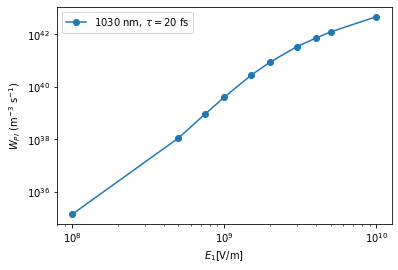

In [39]:
plt.figure()
plt.loglog(Efield1, Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.xlabel(r"$E_1$[V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()

### Results at 515 nm, single pulse, $\tau=20$ fs

In [91]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==20e-15]
data2 = datatmp

Efield1=datatmp.Efield1
# Efield2=datatmp.Efield2
# JobID=datatmp.JobID
RunDate_t=datatmp.RunDate
Nexc=datatmp.N_exc_afterpulse
Wpi=datatmp.Wpi
Wpi_afterpulse=datatmp.Wpi_afterpulse
tau1=datatmp.tau1
AbsEnergy=datatmp.Energy_afterpulse_eV
PolarizationAngle=datatmp.PolarizationAngle
STH=datatmp.STH
# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [92]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
230,5109649.0,20180601.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+08,0.0,0.0,5.150000e-07,...,0.000155,0.000694,-8.547189e+11,5.823872e+24,2.856741e+38,2.911936e+38,3.0,2.0,3762.5,897.845948
1246,8715209.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+08,0.0,0.0,5.150000e-07,...,0.003139,0.019275,-1.380385e+12,1.477673e+26,7.368815e+39,7.388364e+39,3.0,2.0,3125.0,897.845948
1430,8918132.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,7.500000e+08,0.0,0.0,5.150000e-07,...,0.008037,0.053554,1.571800e+13,3.726308e+26,1.860877e+40,1.863154e+40,3.0,2.0,3000.0,897.845948
1096,5027635.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+09,0.0,0.0,5.150000e-07,...,0.018972,0.121628,-4.817450e+13,7.792333e+26,3.895180e+40,3.896167e+40,3.0,2.0,2725.0,897.845948
1564,8918133.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.500000e+09,0.0,0.0,5.150000e-07,...,0.051925,0.405591,9.559337e+13,2.279025e+27,1.138976e+41,1.139513e+41,3.0,2.0,2875.0,897.845948
1405,8649981.0,20190622.0,24.0,0.434637,5.150000e-07,2.000000e-14,2.000000e+09,0.0,0.0,5.150000e-07,...,0.111210,0.906773,1.581342e+14,4.757788e+27,2.377285e+41,2.378894e+41,3.0,2.0,3000.0,897.845948
1541,8715213.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,3.000000e+09,0.0,0.0,5.150000e-07,...,0.204543,1.984661,2.258693e+14,9.294298e+27,4.641914e+41,4.647149e+41,3.0,2.0,3000.0,897.845948
1462,8715214.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,4.000000e+09,0.0,0.0,5.150000e-07,...,0.340320,3.612577,2.309676e+14,1.509498e+28,7.541152e+41,7.547492e+41,3.0,2.0,2750.0,897.845948
126,5027636.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+09,0.0,0.0,5.150000e-07,...,0.455719,6.042565,-3.677350e+14,2.194647e+28,1.097654e+42,1.097324e+42,3.0,2.0,2400.0,897.845948
1027,5027637.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+10,0.0,0.0,5.150000e-07,...,1.446704,41.685514,-4.019898e+15,6.248507e+28,3.126264e+42,3.124253e+42,3.0,2.0,2112.5,897.845948


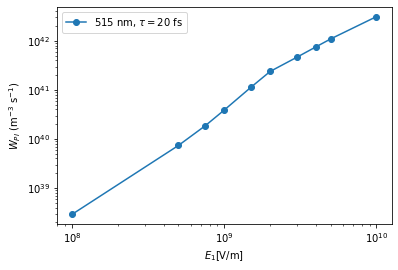

In [42]:
plt.figure()
plt.loglog(Efield1, Wpi_afterpulse, "-o", label=r"515 nm, $\tau=$20 fs")
plt.xlabel(r"$E_1$[V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()

# Bicolor excitation rates

We are looking for the set of bicolor runs available for comparison with experiments

## 1030 nm + 515 nm  at equal fields

In [94]:
from scipy.constants import pi
import numpy as np
# data[data.tau1==20e-15]


## NON-NORMALIZED WAVELENGTH AND PULSE DURATION 

datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==1030e-9] #SELECT WAVELENGTH
datatmp=datatmp[np.fabs(datatmp.lambda2-datatmp.lambda1/2.)<1E-9] #precise filter for lambda1/2=lambda2

datatmp=datatmp[datatmp.Efield2>0]
datatmp=datatmp[datatmp.Efield1==datatmp.Efield2]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.CEP1==0]

# datatmp=datatmp[datatmp.CEP2==-pi/2.]
data3=datatmp
# datatmp=datatmp[datatmp.CEP2==0] ## INSUFFICIENT DATA FOR THIS CASE
# data=data[data.lambda1==3200e-9]
# datatmp=datatmp[datatmp.Efield1==1E9]

## CAPTURING DATA for NORMALIZED FIELD
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9]
# datatmp=datatmp[datatmp.lambda1==1030e-9]
datatmp=datatmp[np.fabs(datatmp.lambda2-datatmp.lambda1/2.)<1E-9]
omega_th = 2*np.pi*c/datatmp.lambda1 
OpticalCycleDuration = 2*np.pi/omega_th
datatmp=datatmp[datatmp.Efield2>0]
datatmp=datatmp[datatmp.Efield1==datatmp.Efield2]

# Selecting CEP
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.CEP2==-pi/2.]

## Selecting pulse durations: note that pulse2 has same absolute duration as pulse1. 
# Preparing data for 1 optical cycle
datatmp_beforetau=datatmp
NumberOfCycles=1
datatmp=datatmp[np.fabs(datatmp.tau1-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
datatmp=datatmp[np.fabs(datatmp.tau2-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
data4=datatmp

# Preparing data for 2 optical cycles
datatmp=datatmp_beforetau
NumberOfCycles=2
datatmp=datatmp[np.fabs(datatmp.tau1-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
datatmp=datatmp[np.fabs(datatmp.tau2-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
data5=datatmp

# Preparing data for 3 optical cycles
datatmp=datatmp_beforetau
NumberOfCycles=3
datatmp=datatmp[np.fabs(datatmp.tau1-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
datatmp=datatmp[np.fabs(datatmp.tau2-NumberOfCycles*OpticalCycleDuration)<1E-15] #selection of OpticalCycles
data6=datatmp

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:44: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:51: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:58: UserWarning: Boolean Series key will be reindexed to match DataFrame index.


In [98]:
print(data6.tau1, data6.tau2)

2355    1.368900e-14
2363    1.368900e-14
2343    1.368900e-14
2356    1.368900e-14
2357    1.368900e-14
2335    1.368900e-14
2349    1.368900e-14
2362    1.368900e-14
2346    1.368900e-14
2354    1.368900e-14
2360    1.368900e-14
2327    1.368900e-14
2338    1.368900e-14
2325    1.368900e-14
2333    1.368900e-14
2340    1.368900e-14
2342    1.368900e-14
2324    1.368900e-14
Name: tau1, dtype: float64 2355    1.368900e-14
2363    1.368900e-14
2343    1.368900e-14
2356    1.368900e-14
2357    1.368900e-14
2335    1.368900e-14
2349    1.368900e-14
2362    1.368900e-14
2346    1.368900e-14
2354    1.368900e-14
2360    1.368900e-14
2327    1.368900e-14
2338    1.368900e-14
2325    1.368900e-14
2333    1.368900e-14
2340    1.368900e-14
2342    1.368900e-14
2324    1.368900e-14
Name: tau2, dtype: float64


## Effect of wavelength, pulses of 30 fs 

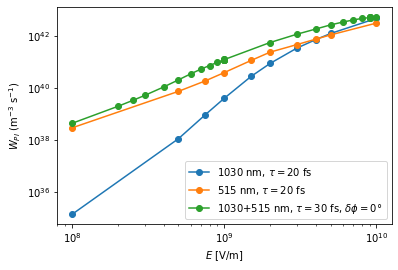

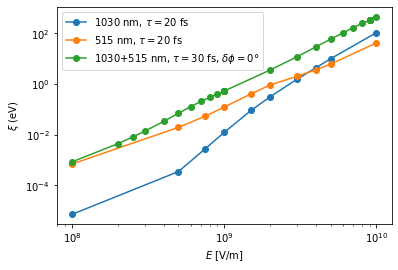

In [99]:
plt.figure()
plt.loglog(data1.Efield1, data1.Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(data2.Efield1, data2.Wpi_afterpulse, "-o", label=r"515 nm, $\tau=20$ fs")
plt.loglog(data3.Efield1, data3.Wpi_afterpulse, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()

plt.figure()
plt.loglog(data1.Efield1, data1.Energy_afterpulse_eV, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(data2.Efield1, data2.Energy_afterpulse_eV, "-o", label=r"515 nm, $\tau=20$ fs")
plt.loglog(data3.Efield1, data3.Energy_afterpulse_eV, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$\xi$ (eV)")
plt.legend()

### Pulses of 1, 2, 3 optical cycles (1030 + 515 nm) (normalized)

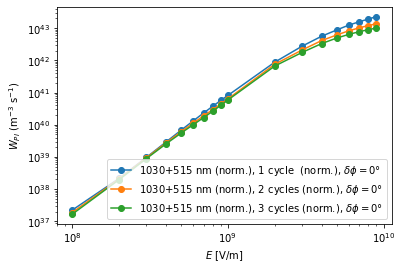

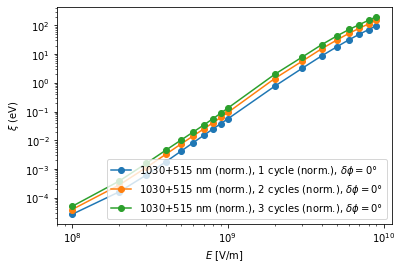

In [101]:
plt.figure()
# plt.loglog(data3.Efield1, data3.Wpi_afterpulse, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.loglog(data4.Efield1, data4.Wpi, "-o", label=r"1030+515 nm (norm.), 1 cycle  (norm.), $\delta \phi = 0°$")
plt.loglog(data5.Efield1, data5.Wpi, "-o", label=r"1030+515 nm (norm.), 2 cycles (norm.), $\delta \phi = 0°$")
plt.loglog(data6.Efield1, data6.Wpi, "-o", label=r"1030+515 nm (norm.), 3 cycles (norm.), $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()

plt.figure()
# plt.loglog(data3.Efield1, data3.Energy_afterpulse_eV, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.loglog(data4.Efield1, data4.Energy_eV, "-o", label=r"1030+515 nm (norm.), 1 cycle (norm.), $\delta \phi = 0°$")
plt.loglog(data5.Efield1, data5.Energy_eV, "-o", label=r"1030+515 nm (norm.), 2 cycles (norm.), $\delta \phi = 0°$")
plt.loglog(data6.Efield1, data6.Energy_eV, "-o", label=r"1030+515 nm (norm.), 3 cycles (norm.), $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$\xi$ (eV)")
plt.legend()

# Preparing pulses for conserving number of cycles

In [18]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 10_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

wavelength = 1.3679687500000002e-06; tau=4.5630525835309716e-15 #1 cycle of 1030 nm renormalized with LDA->EXP band gap
# wavelength = 2656e-9; tau=13e-15 #Kozak experimental, pulse rescaled for TDDFT LDA
#wavelength = 3200e-9; tau=30e-15 #Pulse used for orientation-dep excitation rate
CEP=0e0 #1*pi

omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")
print("Number of cycles: "+str(tau/T)+" cycles")

One-cycle period: 4.5630525835309716e-15 seconds
Frequency in Hz:  1.3769697350972767 PHz
Number of cycles: 1.0 cycles


## Gaussian pulses

In [19]:
t0 = 2*tau #central time
tmin = 0; tmax = 10*t0; #size of the window: controls energy precision. 
# Solution for increasing FFT spectrum precision: increase size of initial signal table, just fill it with zeros.
t = np.linspace(tmin, tmax, N, endpoint=False)
TimeStep=np.diff(t)[0]
print("Timestep: "+str(TimeStep)+" s")
# print(omega*t)
## TODO: replace with pulse from spp_extended_theory STH !
sigma_tau=tau/(2.*np.sqrt(2.*np.log(2.)))
y = np.exp(-0.5*((t-t0)/sigma_tau)**2) * np.sin(omega*t+CEP) #+ 0.5*np.sin(80.0 * 2.0*np.pi*t)
# y.resize(30000,)

Timestep: 9.126105167061943e-18 s


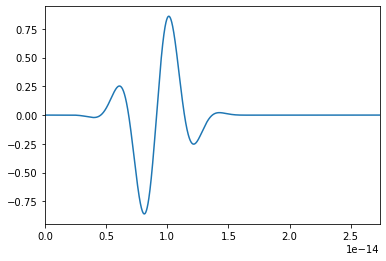

In [20]:
plt.figure()
plt.plot(t,y)
# plt.plot(Envelope[0],Envelope[1])
plt.xlim([0,6*tau])
plt.show()

In [21]:
from scipy.constants import epsilon_0
0.5*c*epsilon_0*(1E9)**2 / 1E11 /1E4

1.3272093639964782

It is well seen that Gaussian pulses never fall to zero at the beginning of the pulse. 

## Generation of STH pulse, same as in octopus

In [22]:
# from octopus_slabs.Pulses.GeneratePulse import GeneratePulse
from spp_extended_theory.Keldysh.libKeldyshPulses import PulseSmoothTopHatShape
from scipy.constants import pi

# wavelength=1030e-9
RiseCycle=2
PulseDelay=0e0
power=2

omega = 2.*pi*c/wavelength
tauRise = 2.*pi*RiseCycle / (omega)
print("Rise cycle duration: ", tauRise, "seconds")
ComputingT = 7./5.*(tauRise+tau+tauRise+PulseDelay)
print("Computing physical time range: ", ComputingT, "seconds")
PeakField = 1E9


tmin = 0e-15
tmax = float(ComputingT)
Number = 50000 #NOTE: better to put too many nodes here ! Better to have something wider than planned octopus time steps. 
timestep=(tmax-tmin)/(Number+1.)
t = np.arange(tmin, tmax, timestep)
tauSafe = wavelength / c #1 optical cycle to ensure having dA/dt = 0 at instant zero !
Envelope, Field = PulseSmoothTopHatShape(t, tau, tauRise, PeakField, wavelength, CEP, t0+tauSafe, PulseDelay, power)
# Envelope     = GeneratePulse(t, tau, tauRise, PeakField, wavelength, 2.*pi*CEP, tau/2.+tauRise+tauSafe, PulseDelay+0.1E-15, power)
# print(Field)

Rise cycle duration:  9.126105167061943e-15 seconds
Computing physical time range:  3.19413680847168e-14 seconds


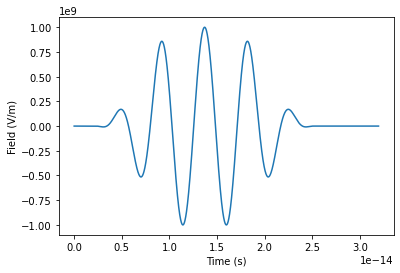

In [23]:
plt.figure()
plt.plot(t,np.real(Field))
# plt.plot(Envelope[0]*timestep,Envelope[1])
plt.xlabel("Time (s)")
plt.ylabel("Field (V/m)")
# plt.xlim([0,6*tau])
plt.show()

## Normalization of wavelength to bandgap

Each pulse should be renormalized to the functional band gap energy

$\frac {\hbar \omega_{th}} {E_g^{LDA}} = \frac{\hbar \omega_{exp}}{ E_g^{exp} }$

In [24]:
wavelength_exp = 1030e-9 #or 2300e-9 ? 
Eg_exp = 3.4*e #direct band gap at 300 K
Eg_th  = 2.56*e

wavelength_th = Eg_exp/Eg_th * wavelength_exp

print(wavelength_th)

1.3679687500000002e-06


### Deducing pulse duration from normalized wavelength

In [25]:
number_cycles = 1 #cycles

omega_exp = 2*pi*c/wavelength_exp
omega_th = 2*pi*c/wavelength_th

T_exp = 2*np.pi/omega_exp
T_th  = 2*np.pi/omega_th

tau_th = number_cycles * T_th
print("Renormalized pulse duration: ", tau_th)

Renormalized pulse duration:  4.5630525835309716e-15


In [26]:
1.3679687500000002e-06/2

6.839843750000001e-07